# 03. One decision tree

A single classification tree splits the data on one feature at a time, choosing the split that most
reduces impurity (Gini). It is the most readable model there is, and the building block of every model
that follows. Here: **is the phosphate class good or better?**

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))

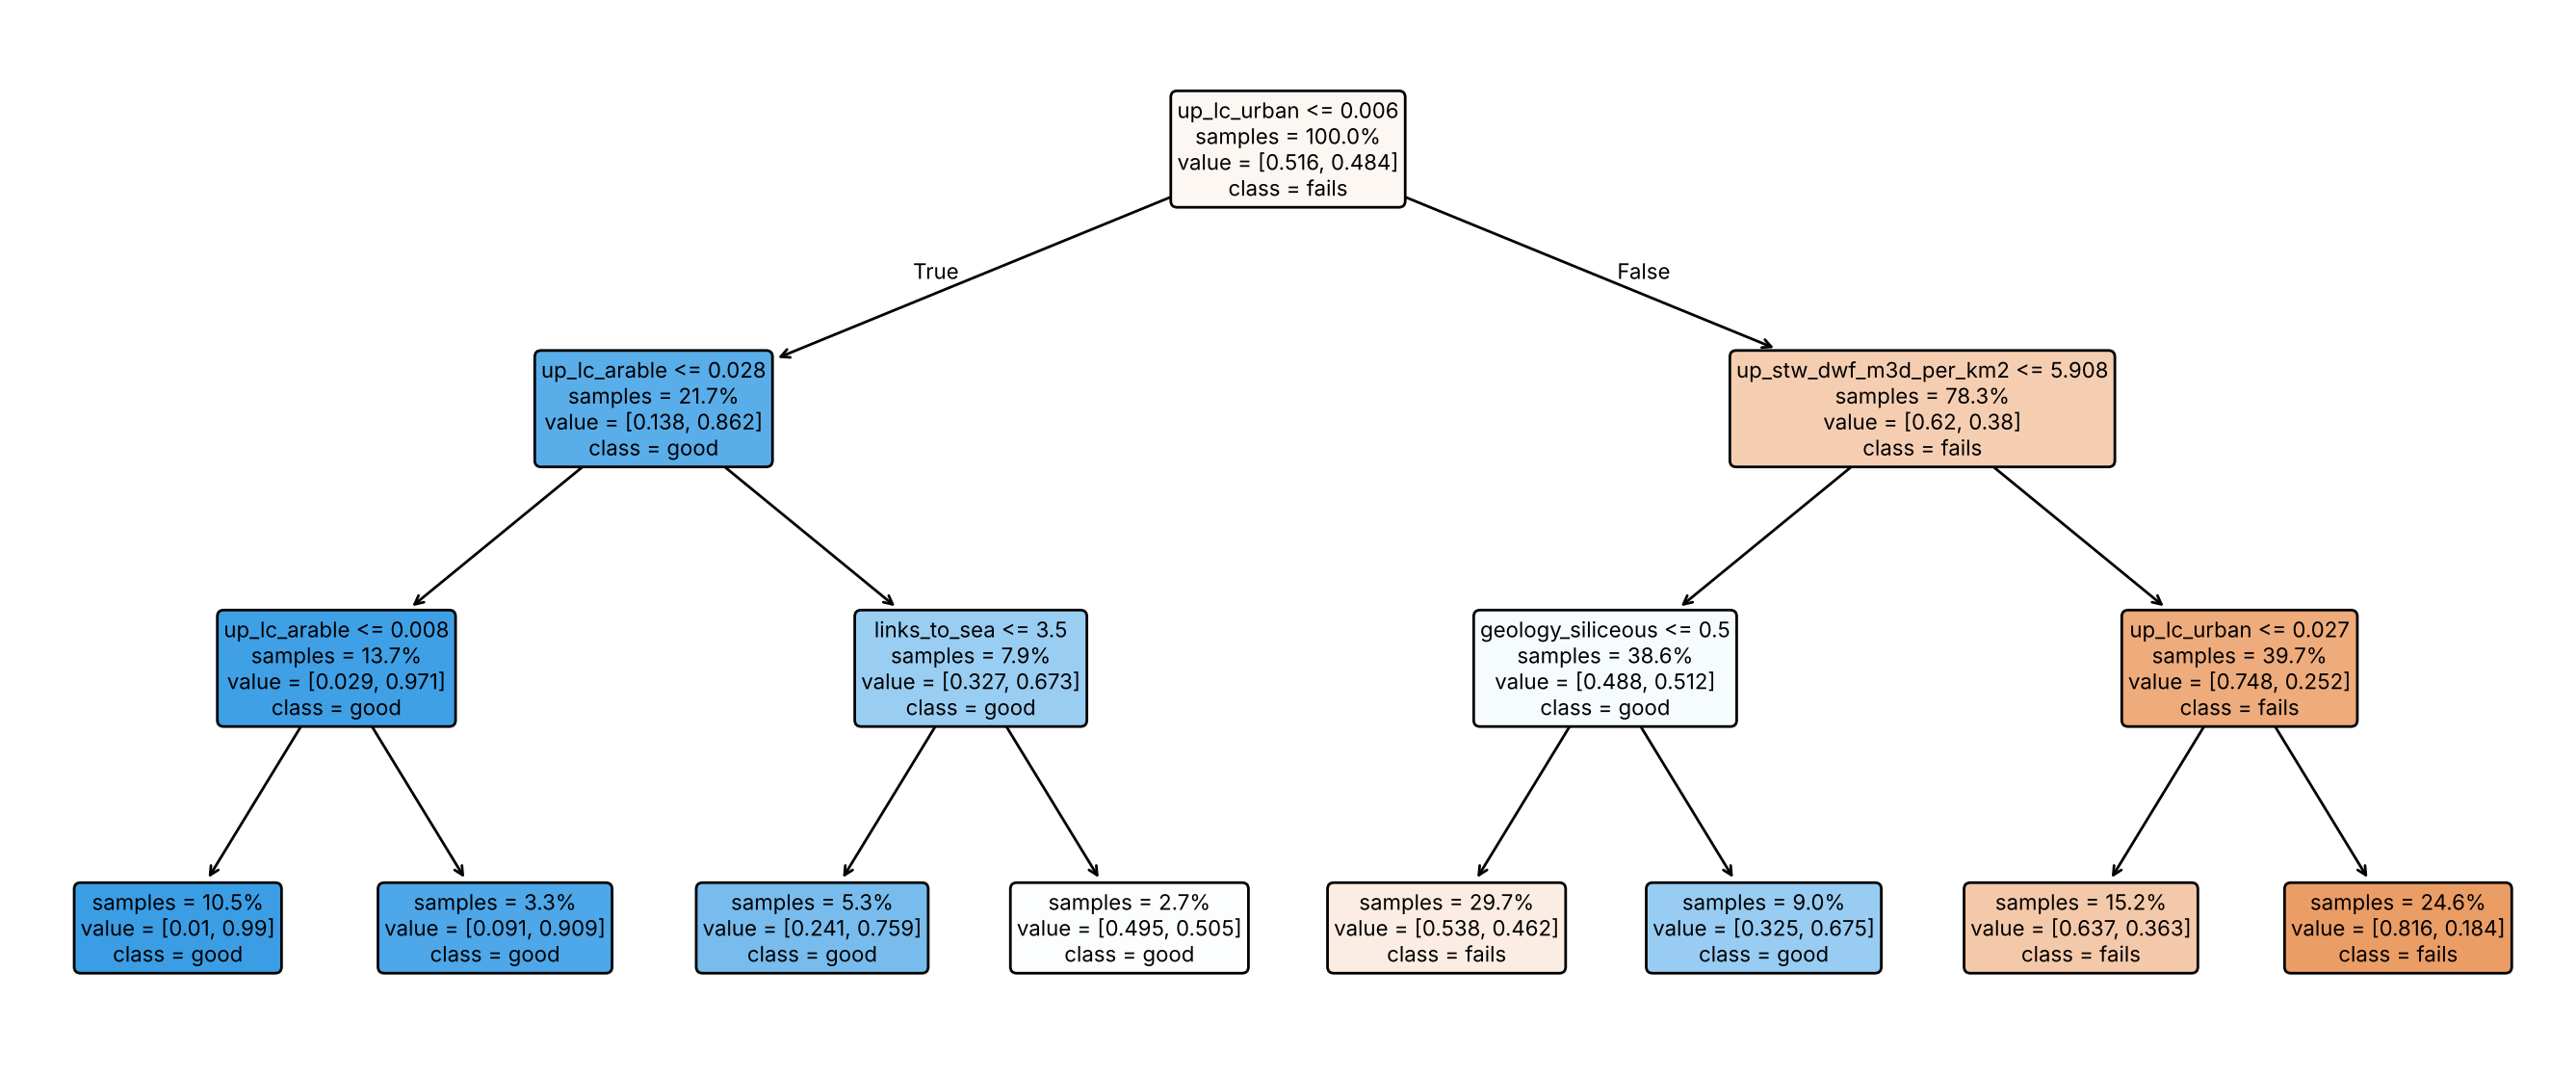

In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
feats = M.FEATURE_SETS["pressures"]
X, y, g, d = M.xy(t, "phos_good", feats)
pre = M._onehot_pre(feats).fit(X)
Xp = pd.DataFrame(pre.transform(X), columns=pre.get_feature_names_out())
small = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=0).fit(Xp, y)
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(small, feature_names=Xp.columns, class_names=["fails", "good"], filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=8, ax=ax)
plt.show()

The first split asks whether there is **any built-up land upstream** (more than about 1% of the catchment).
Rivers without it are then split by arable land. Rivers with it are split by **sewage works dry-weather flow
per km² upstream**: how much treated sewage the river receives relative to the catchment that dilutes it.
Above about 6 m³/day per km², most rivers fail. That is the textbook phosphorus story (sewage first, then
farming), rediscovered from data.

## How big should the tree be? Cost-complexity pruning, judged on unseen catchments

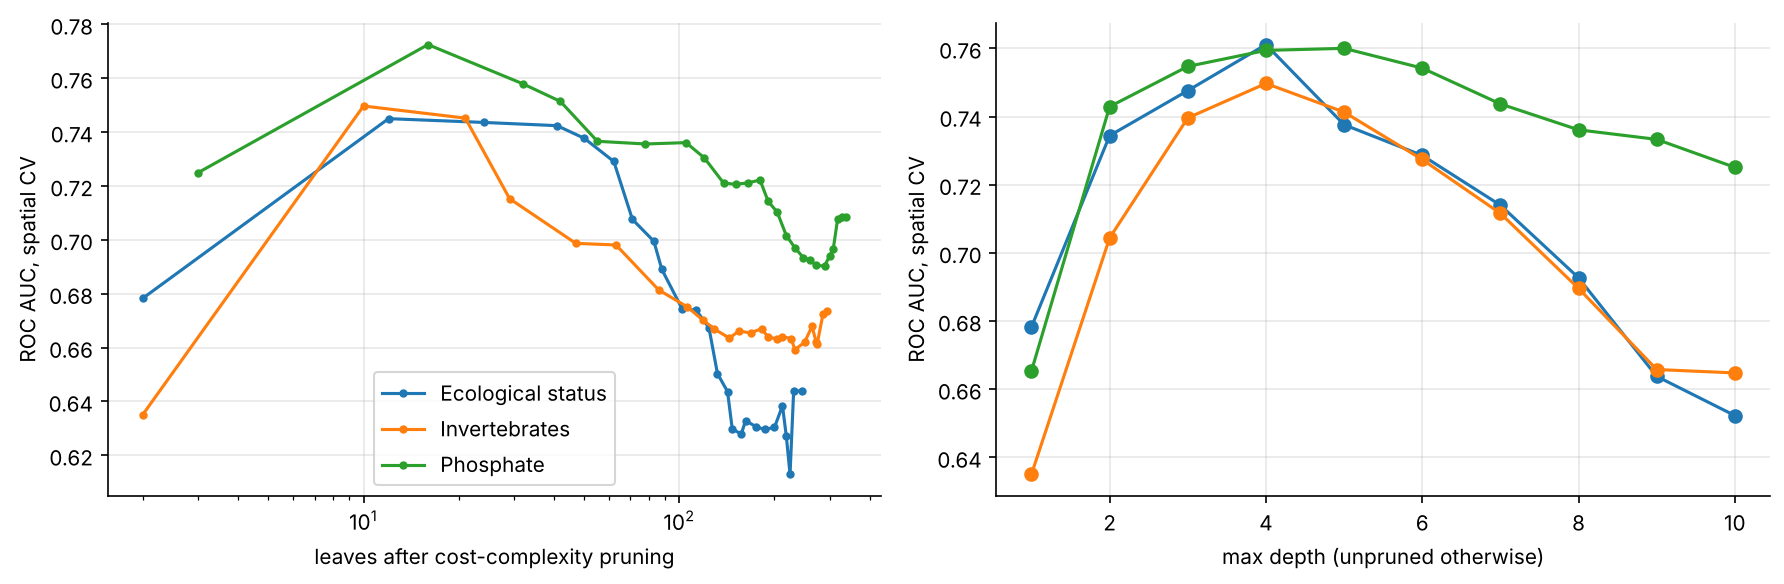

,target,ccp_alpha,leaves,depth,roc_auc,log_loss
93,phos_good,0.0023,16.0,8.0,0.7725,0.5668
58,inv_good,0.0019,10.0,5.0,0.7497,0.4798
23,eco_good,0.0012,12.0,6.0,0.7450,0.4532


In [3]:
display(Image(FIG / "tree_pruning.png"))
p = pd.read_csv(T / "tree_pruning.csv")
best = p[p.ccp_alpha.notna()].sort_values("roc_auc", ascending=False).groupby("target").head(1)
best[["target", "ccp_alpha", "leaves", "depth", "roc_auc", "log_loss"]].round(4)

A fully grown tree memorises the training catchments, and its AUC on unseen catchments collapses.
Pruning trades leaves against fit: the cost-complexity criterion minimises
$R(T) + \alpha |T|$, where $|T|$ is the number of leaves. The best spatially validated trees keep only
10-16 leaves (AUC 0.75-0.77) and still trail the ensembles in notebooks 04 and 05 by 0.05 AUC.

## The weakness ensembles fix: instability

In [4]:
rng = np.random.default_rng(0)
shapes, thresholds = [], []
for b in range(30):
    i = rng.choice(len(y), len(y), replace=True)
    m = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=b).fit(Xp.iloc[i], y[i])
    tr = m.tree_
    used = sorted({Xp.columns[f] for f in tr.feature if f >= 0})
    shapes.append(" | ".join(used))
    thresholds.append(tr.threshold[0])
print("root threshold on", Xp.columns[m.tree_.feature[0]], "across 30 resamples:",
      np.round(np.quantile(thresholds, [0.05, 0.5, 0.95]), 4))
print("distinct sets of split features in 30 depth-4 trees:", len(set(shapes)))
pd.Series(shapes).value_counts().head(5)

root threshold on up_lc_urban across 30 resamples: [0.0061 0.0069 0.0109]
distinct sets of split features in 30 depth-4 trees: 30


altitude_mid | geology_calcareous | geology_siliceous | links_to_sea | up_area_km2 | up_lc_arable | up_lc_improved_grass | up_lc_urban | up_lc_wetland_bog | up_lc_woodland | up_stw_dwf_m3d_per_km2                       1
geology_siliceous | links_to_sea | local_stw_dwf_m3d | up_area_km2 | up_lc_arable | up_lc_improved_grass | up_lc_urban | up_lc_woodland | up_n_private_sewage_per_km2 | up_spill_count_per_km2 | up_stw_dwf_m3d_per_km2    1
geology_siliceous | links_to_sea | up_lc_arable | up_lc_improved_grass | up_lc_urban | up_lc_water | up_lc_wetland_bog | up_lc_woodland | up_stw_dwf_m3d_per_km2                                                           1
local_n_private_sewage | local_stw_dwf_m3d | up_area_km2 | up_lc_arable | up_lc_seminatural | up_lc_urban | up_lc_water | up_lc_wetland_bog | up_stw_dwf_m3d_per_km2                                                       1
geology_siliceous | links_to_sea | local_spill_hours | local_spill_hours_stw | up_area_km2 | up_lc_arable | up_lc_se

The root split is stable, but the rest of the tree is not: almost every resample uses a different set of
features below the root. Correlated pressures (urban land, sewage flow, overflows) substitute for each other.
Averaging many trees (random forest) or adding small corrective trees (boosting) removes most of that variance.

In [5]:
print(export_text(small, feature_names=list(Xp.columns), decimals=2))

|--- up_lc_urban <= 0.01
|   |--- up_lc_arable <= 0.03
|   |   |--- up_lc_arable <= 0.01
|   |   |   |--- class: 1
|   |   |--- up_lc_arable >  0.01
|   |   |   |--- class: 1
|   |--- up_lc_arable >  0.03
|   |   |--- links_to_sea <= 3.50
|   |   |   |--- class: 1
|   |   |--- links_to_sea >  3.50
|   |   |   |--- class: 1
|--- up_lc_urban >  0.01
|   |--- up_stw_dwf_m3d_per_km2 <= 5.91
|   |   |--- geology_siliceous <= 0.50
|   |   |   |--- class: 0
|   |   |--- geology_siliceous >  0.50
|   |   |   |--- class: 1
|   |--- up_stw_dwf_m3d_per_km2 >  5.91
|   |   |--- up_lc_urban <= 0.03
|   |   |   |--- class: 0
|   |   |--- up_lc_urban >  0.03
|   |   |   |--- class: 0

